# 6차 실험: 이웃 라벨 특성 (kNN label features)

| 항목 | 내용 |
|---|---|
| 목표 | 4차 최고점(스태킹 33개 + 임계값, CV F1 0.8282)을 넘는다 |
| 아이디어 | 예측 데이터는 학습 데이터와 구조가 비슷한 화합물이 많다(유사도 0.8 이상 53%). 가장 비슷한 학습 화합물들의 라벨을 직접 특성으로 주면 도움이 될 수 있다 |
| 특성 | ECFP·FCFP 각각: 최대 유사도, 상위 5개 평균 유사도, 유사도 가중 라벨 평균(k = 1, 3, 5, 10), 유사도 0.7 이상 이웃의 라벨 평균과 개수 → 16개 |
| 누수 방지 | 이웃은 항상 그 모델의 학습 데이터 안에서만 찾는다. 학습 행은 자기 자신을 뺀 이웃(leave-one-out), 검증·테스트·예측 행은 학습 데이터 전체가 이웃 후보 (`knnfeat.KnnAugmented`) |
| 모델 | ① 3차 튜닝 모델 3개(+MACCS 입력) + 이웃 특성 ② 이웃 특성 16개 + 연속형 15개만 쓰는 작은 모델 2개 (LightGBM, 로지스틱 회귀) — 앙상블에서 다른 관점 |
| 비교 | 단독: 3차 같은 모델과 / 앙상블: 4차 최종 스태킹 vs 33개 + 6차 모델 (같은 10 fold, fold 안 임계값, 짝지은 보정 t-검정) |

실행 약 20분. `RUN_CV = False`면 저장 결과를 불러온다.

In [1]:
import sys, time, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
HERE = Path.cwd(); M = HERE.parent
for p in ("common", "exp03_tuning"): sys.path.insert(0, str(M / p))
sys.path.insert(0, str(HERE))
from preprocess import preprocess_train
from evaluate import load_splits, run_cv, corrected_paired_ttest
from load_features import load_all
from knnfeat import full_fp
import models6, stacking as S

warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
RES = HERE / "results"; RES.mkdir(exist_ok=True)
RUN_CV = True

## 1. 데이터

In [2]:
df, X, y, groups = preprocess_train(M.parent / "train.csv"); df = load_splits(df)
ALL = pd.concat([load_all(df, X), full_fp(df).reset_index(drop=True)], axis=1)
dev = (df.set == "dev").values
Xd = ALL[dev].reset_index(drop=True); yd = y[dev]; smi = df.loc[dev, "SMILES"].values
folds = df.loc[dev, ["fold_r0", "fold_r1"]].reset_index(drop=True)
print("개발 세트:", Xd.shape)

개발 세트: (6400, 7423)


## 2. 6차 모델 10-fold 교차검증

In [3]:
if RUN_CV:
    sc, oo = [], {}
    for name in models6.NAMES:
        mk, use = models6.build(name); t0 = time.time()
        s, o = run_cv(mk, Xd[use], yd, folds, name)
        sc.append(s)
        for r in o.columns: oo[f"{name}|{r}"] = o[r].values
        print(f"{name:18s} F1 {s.f1.mean():.4f} ± {s.f1.std(ddof=0):.4f} | AUC {s.auc.mean():.4f} | {time.time()-t0:.0f}s", flush=True)
    scores = pd.concat(sc, ignore_index=True)
    oof = pd.DataFrame(oo); oof.insert(0, "SMILES", smi); oof.insert(1, "label", yd)
    scores.to_csv(RES / "cv_scores.csv", index=False); oof.to_csv(RES / "oof_predictions.csv", index=False)
else:
    scores = pd.read_csv(RES / "cv_scores.csv"); oof = pd.read_csv(RES / "oof_predictions.csv")

knn|LightGBM       F1 0.8091 ± 0.0074 | AUC 0.8733 | 158s


knn|XGBoost        F1 0.8105 ± 0.0061 | AUC 0.8728 | 170s


knn|RandomForest   F1 0.7991 ± 0.0051 | AUC 0.8601 | 157s


knnonly|LightGBM   F1 0.7941 ± 0.0048 | AUC 0.8542 | 25s


knnonly|LogReg     F1 0.7962 ± 0.0067 | AUC 0.8538 | 23s


## 3. 단독 비교: 이웃 특성을 붙이기 전(3차 튜닝 모델)과

In [4]:
s3 = pd.read_csv(M / "exp03_tuning/results/cv_scores.csv")
rows = []
for algo in ("LightGBM", "XGBoost", "RandomForest"):
    a = s3[s3.model == f"tuned|{algo}"].sort_values(["repeat", "fold"]); b = scores[scores.model == f"knn|{algo}"].sort_values(["repeat", "fold"])
    d = b.f1.values - a.f1.values
    rows.append((algo, a.f1.mean(), b.f1.mean(), d.mean(), S.paired_p(d), int((d > 0).sum()), a.auc.mean(), b.auc.mean()))
single = pd.DataFrame(rows, columns=["모델", "3차 F1", "+이웃 특성 F1", "차이", "p값", "10 fold 중 개선", "3차 AUC", "+이웃 AUC"]).set_index("모델")
display(single.round(4))
display(scores.groupby("model")[["f1", "auc", "precision", "recall"]].mean().sort_values("f1", ascending=False).round(4))

,3차 F1,+이웃 특성 F1,차이,p값,10 fold 중 개선,3차 AUC,+이웃 AUC
모델,,,,,,,
LightGBM,0.8215,0.8091,-0.0124,0.0016,0,0.8832,0.8733
XGBoost,0.8218,0.8105,-0.0113,0.0027,0,0.8824,0.8728
RandomForest,0.8212,0.7991,-0.0221,0.0000,0,0.8772,0.8601


,f1,auc,precision,recall
model,,,,
knn|XGBoost,0.8105,0.8728,0.7998,0.8218
knn|LightGBM,0.8091,0.8733,0.7961,0.8228
knn|RandomForest,0.7991,0.8601,0.7821,0.8172
knnonly|LogReg,0.7962,0.8538,0.7854,0.8075
knnonly|LightGBM,0.7941,0.8542,0.7828,0.8060


## 4. 앙상블: 4차 최종 vs 4차 + 6차 모델

,방법,F1@0.5,F1(fold 안 임계값),F1_std,AUC,4차 최종 대비,p값,10 fold 중 개선,임계값(중앙값)
0,4차 최종: 스태킹 33개,0.8235,0.8282,0.0070,0.8866,0.0000,NaN,0,0.425
1,스태킹 33개 + 새 모델,0.8224,0.8257,0.0060,0.8866,-0.0025,0.2392,2,0.430
2,스태킹: 3차 튜닝 3개 + 6차 5개,0.8222,0.8241,0.0061,0.8842,-0.0041,0.1892,2,0.430
3,스태킹 33개 + 6차 작은 모델 2개,0.8231,0.8267,0.0051,0.8866,-0.0015,0.5239,5,0.425


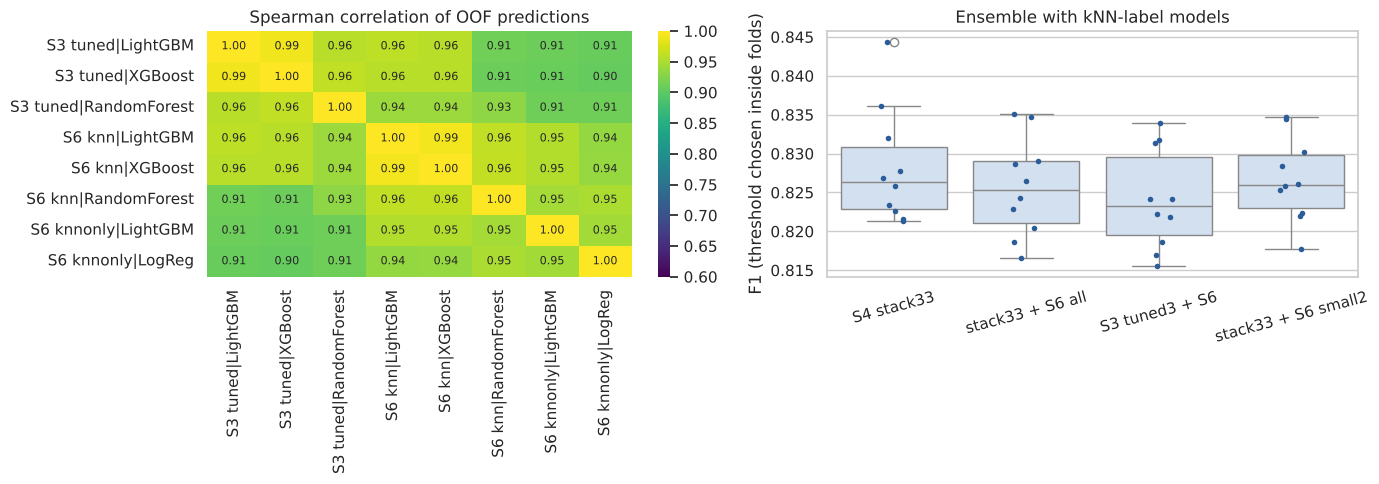

In [5]:
pool = S.base_pool(smi); base_names = list(pool)
pool.update(S.read_oof(RES / "oof_predictions.csv", "6차:", smi))
new = [f"6차:{n}" for n in models6.NAMES]
tuned = [k for k in base_names if k.startswith("3차:")]
extra = {"스태킹: 3차 튜닝 3개 + 6차 5개": S.m_stack(pool, tuned + new, yd, C=1.0),
         "스태킹 33개 + 6차 작은 모델 2개": S.m_stack(pool, base_names + new[3:], yd, C=0.1)}
tbl, res = S.compare_with_s4(pool, base_names, new, yd, folds, extra)
tbl.to_csv(RES / "ensemble_compare.csv", index=False)
display(tbl.round(4))

P = pd.DataFrame({k.replace("3차:", "S3 ").replace("6차:", "S6 "): pool[k]["r0"] for k in tuned + new})
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(P.corr(method="spearman"), annot=True, fmt=".2f", cmap="viridis", vmin=0.6, vmax=1, ax=ax[0], annot_kws={"size": 8})
ax[0].set_title("Spearman correlation of OOF predictions")
long = pd.concat([r.assign(method=n) for n, r in res.items()])
long["method"] = long.method.map({"4차 최종: 스태킹 33개": "S4 stack33", "스태킹 33개 + 새 모델": "stack33 + S6 all",
                                  "스태킹: 3차 튜닝 3개 + 6차 5개": "S3 tuned3 + S6", "스태킹 33개 + 6차 작은 모델 2개": "stack33 + S6 small2"})
sns.boxplot(data=long, x="method", y="f1_thr", ax=ax[1], color="#cfe0f3"); sns.stripplot(data=long, x="method", y="f1_thr", ax=ax[1], color="#2b5d9a", size=4)
ax[1].set_xlabel(""); ax[1].set_ylabel("F1 (threshold chosen inside folds)"); ax[1].set_title("Ensemble with kNN-label models"); ax[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.savefig(RES / "fig_knn.png", dpi=130); plt.show()

## 5. 6차 최종 방법 확정 (제출 파일에 사용)
- 6차 모델이 들어간 방법 중 F1(fold 안 임계값)이 가장 높은 것을 6차 최종으로 한다.

In [6]:
cand = tbl[tbl["방법"] != "4차 최종: 스태킹 33개"].sort_values("F1(fold 안 임계값)", ascending=False).iloc[0]
METHOD = cand["방법"]
names = {"스태킹 33개 + 새 모델": base_names + new, "스태킹: 3차 튜닝 3개 + 6차 5개": tuned + new,
         "스태킹 33개 + 6차 작은 모델 2개": base_names + new[3:]}[METHOD]
Cc = 1.0 if METHOD.startswith("스태킹: 3차") else 0.1
final = S.finalize(pool, names, yd, Cc, RES / "final_method.json", METHOD, cand["F1(fold 안 임계값)"])
print(METHOD, "| 모델 수", len(names), "| 임계값", final["threshold"], "| CV F1", round(final["cv_f1"], 4),
      "| 4차 최종 대비", round(cand["4차 최종 대비"], 4), "(p=", round(cand["p값"], 3), ")")

스태킹 33개 + 6차 작은 모델 2개 | 모델 수 35 | 임계값 0.42 | CV F1 0.8267 | 4차 최종 대비 -0.0015 (p= 0.524 )


## 6. 결론

결과 표와 그래프는 위 절 참고.

### 판단
1. 이웃 라벨 특성은 단독으로도, 앙상블에서도 해롭다. 세 모델 모두 10 fold 전부에서 떨어졌다.
2. 원인: 구조가 거의 같은 화합물끼리도 라벨 일치율이 0.81이라 이웃 라벨에 노이즈가 많다. 트리는 이 강력해 보이는 특성에 먼저 분할을 걸어, 원래 특성(clogp·TPSA·Fingerprint)을 덜 쓰게 된다.
3. 이웃 라벨 정보는 이미 Fingerprint를 통해 트리 모델이 간접적으로 쓰고 있었다. 다시 명시적으로 주는 것은 추가 정보가 아니었다.
4. 4차 최종을 그대로 최고로 유지한다.

### 제출 파일
- `predict_output_임채현_6차.csv`: 6차 최고(스태킹 33개 + 6차 작은 모델 2개, CV F1 0.8267). 4차보다 낮으므로 제출은 권하지 않는다. 테스트 점수는 `results/test_score.csv`.

